<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">Futbol, Futebol &amp; Soccer: 9 Leagues of the Americas — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">Every figure of the listing, recomputed from the files of the full product:
30,999 matches from the top division of 9 countries (MLS, Liga MX, Brasileirão, Argentina, Colombia, Chile,
Ecuador, Bolivia, Venezuela), 73,680,541 timestamped quotes from 5 named bookmakers incl. Pinnacle,
1,781,722 snapshots from 37 more bookmakers, 2016–2026.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing,
recomputes it from the files and prints **PASS** or **FAIL**. The expected values are written once, in plain
sight, in the `CLAIMS` cell; everything else is read from the data.

⚽ **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/diswpw?utm_source=github&utm_medium=notebook&utm_campaign=americas_premium&utm_content=notebook_top)** · free 20-match sample: same files, same columns.

## 0 · Setup

In [1]:
import os, glob, hashlib, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

def find_root():
    """Folder of the full product: the Americas_Matches.csv with the most rows wins (sample and full may both be attached)."""
    hits = []
    for base in (os.environ.get("AM_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += glob.glob(os.path.join(base, "**", "Americas_Matches.csv"), recursive=True)
    if not hits:
        raise FileNotFoundError("Americas_Matches.csv not found: attach the dataset to this notebook")
    return os.path.dirname(max(hits, key=os.path.getsize))

ROOT = find_root()
print("Product folder:", ROOT)

def table_files(prefix):
    """The 9 per-league files of a table, wherever they sit under the product folder:
    .csv.gz as shipped, or .csv when the hosting platform stores them decompressed."""
    for ext in (".csv.gz", ".csv"):
        # files only: Kaggle stores each decompressed .csv.gz as a folder "X.csv" that holds the file "X.csv"
        hits = sorted(p for p in glob.glob(os.path.join(ROOT, "**", prefix + "*" + ext), recursive=True)
                      if os.path.isfile(p))
        if hits:
            return hits
    return []

def stem(path):
    """File name without folder or extension: the key of the MANIFEST row counts."""
    b = os.path.basename(path)
    return b[:-7] if b.endswith(".csv.gz") else b.rsplit(".", 1)[0]

FILES = {t: table_files(p) for t, p in (("odds", "Americas_Odds_Timestamped_"),
                                        ("snapshots", "Americas_Bookmaker_Snapshots_"),
                                        ("events", "Americas_Events_"), ("lineups", "Americas_Lineups_"),
                                        ("minute_stats", "Americas_Minute_Stats_"))}
for t, fs in FILES.items():
    kinds = sorted({".csv.gz" if f.endswith(".gz") else ".csv" for f in fs}) or ["none found"]
    print(f"{t:13} {len(fs):>2} files  ({', '.join(kinds)})")
assert all(len(fs) == 9 for fs in FILES.values()), \
    "each table should have 9 files, one per league: is the dataset fully processed on this platform?"

# Olivier Sports Data dark signature. HDA = home / draw / away, checked for colour-blind and normal-vision
# separation on this background.
BG, FG, FG2, GRID, CYAN = "#080c10", "#e6edf3", "#9aa7b2", "#1c2630", "#00d4ff"
HDA = {"Home": "#00a3cc", "Draw": "#c98500", "Away": "#d55181"}
BOOK_COLOR = {"Bet365": "#00d4ff", "Pinnacle": "#f0c75e", "Unibet": "#7bd88f", "Betfair": "#d55181", "Betsson": "#b59cff"}
plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GRID, "axes.labelcolor": FG2, "xtick.color": FG2, "ytick.color": FG2,
    "text.color": FG, "axes.titlecolor": FG, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10.5,
    "legend.frameon": False, "figure.dpi": 110,
})

RESULTS = []
def check(claim, ok, detail=""):
    RESULTS.append((claim, bool(ok), detail))
    print(("PASS  " if ok else "FAIL  ") + claim + (f"   [{detail}]" if detail else ""))

def epoch(s):
    """ISO 8601 UTC 'YYYY-MM-DDTHH:MM:SSZ' -> Unix seconds (NaN when empty)."""
    t = pd.to_datetime(s, format="%Y-%m-%dT%H:%M:%SZ", utc=True, errors="coerce")
    return (t - pd.Timestamp("1970-01-01", tz="UTC")).dt.total_seconds()

BOOKS = ["Bet365", "Pinnacle", "Unibet", "Betfair", "Betsson"]
KNOCKOUT = ["Play-In", "Round of 16", "Quarter-finals", "Semi-finals", "Third Place", "Final", "Play-Offs"]

Product folder: ./Futbol_Futebol_Soccer_Premium_2016-2026
odds           9 files  (.csv.gz)
snapshots      9 files  (.csv.gz)
events         9 files  (.csv.gz)
lineups        9 files  (.csv.gz)
minute_stats   9 files  (.csv.gz)


## 1 · The claims

Copied from the listing and the README. Nothing below is adjusted to fit: if the files disagree, the cell prints FAIL.

In [2]:
CLAIMS = {
    'matches': 30_999,
    'leagues': 9,
    'league_seasons': 96,
    'editions': 143,
    'first_kickoff_on': '2016-08-28',
    'last_kickoff_before': '2026-10-01T00:00:00Z',
    'matches_per_league': {
        'ARG': 4_717, 'BOL': 2_803, 'BRA': 3_866, 'CHI': 2_147, 'COL': 4_098, 'ECU': 2_645, 'MEX': 3_347,
        'USA': 4_589, 'VEN': 2_787,
    },
    'knockout': {
        'matches': 911, 'single': 262, 'two_legged_ties': 288, 'third_matches': 1, 'lone_second_legs': 7,
        'lone_first_legs': 5, 'bo3_series': 24, 'bo3_games': 60,
    },
    'extra_time': 43,
    'penalty_shootouts': 116,
    'shootouts_without_extra_time': 90,
    'neutral_venue': {'neutral': 38, 'home_country': 29_619, 'unknown': 1_342},
    'round_filled': 25_394,
    'quotes': 73_680_541,
    'in_play': 58_887_358,
    'pre_match': 14_793_183,
    'quotes_per_book': {
        'Bet365': 53_681_928, 'Pinnacle': 2_566_889, 'Unibet': 5_036_170, 'Betfair': 10_750_348,
        'Betsson': 1_645_206,
    },
    'in_play_score_and_clock': {
        'Bet365': 48_533_176, 'Pinnacle': 34, 'Unibet': 4_746_386, 'Betfair': 821_105, 'Betsson': 1_060_769,
    },
    'pre_match_with_minute': {'Bet365': 874, 'Pinnacle': 0, 'Unibet': 0, 'Betfair': 0, 'Betsson': 0},
    'ft_1x2_close_per_book': {
        'Bet365': 30_893, 'Pinnacle': 23_110, 'Unibet': 28_000, 'Betfair': 5_857, 'Betsson': 12_582,
    },
    'median_close_gap': {
        'Bet365': '25 min', 'Betfair': '5 min', 'Betsson': '11 min', 'Pinnacle': '4 min', 'Unibet': '1.7 h',
    },
    'coverage_from': {
        'Bet365': '2016-08-28', 'Pinnacle': '2018-09-27', 'Unibet': '2017-04-15', 'Betfair': '2023-11-03',
        'Betsson': '2022-07-03', 'Minute_Stats': '2017-06-10', 'Events': '2016-08-28',
    },
    'coverage_gaps': {
        'Bet365': [], 'Pinnacle': [['2023-09', '2023-11'], ['2026-07', '2026-08']],
        'Unibet': [['2026-07', '2026-08']], 'Betfair': [['2024-11', '2025-08'], ['2026-07', '2026-08']],
        'Betsson': [['2025-12', '2025-12'], ['2026-07', '2026-08']],
        'Minute_Stats': [['2018-02', '2019-09'], ['2026-07', '2026-07']], 'Events': [],
    },
    'coverage_stops': {
        'Bet365': {}, 'Pinnacle': {}, 'Unibet': {}, 'Betfair': {}, 'Betsson': {}, 'Minute_Stats': {}, 'Events': {},
    },
    'mls_matches': 4_589,
    'mls_start_5_to_30_min_late': 4_405,
    'source_kickoff_over_3h_late': 7,
    'snapshots': 1_781_722,
    'snapshot_books': 37,
    'team_stats': 61_998,
    'lineups': 983_966,
    'events': 954_808,
    'minute_stats': 8_353_269,
    'minute_stats_time': {'from': '2021-05-11', 'matches_without': 5_535, 'rows_without': 2_102_874},
    'example_in_play_bet365_1x2': 255,
}

## 2 · Every file is the one that was shipped

`MANIFEST.csv` lists each file with its row count and SHA-256 fingerprint. Recomputing the fingerprints proves
that nothing was altered between the build and this notebook.

In [3]:
man = pd.read_csv(os.path.join(ROOT, "MANIFEST.csv"), dtype=str)
located = {}
for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True):
    if os.path.isfile(p):
        located.setdefault(os.path.basename(p), p)
t0, missing, altered, decompressed, hashed = time.time(), [], [], [], 0
for f, h in zip(man["File"], man["SHA256"]):
    p = os.path.join(ROOT, *f.split("/"))
    if not os.path.exists(p):
        p = located.get(os.path.basename(f))
    if p is None and f.endswith(".gz") and os.path.basename(f)[:-3] in located:
        decompressed.append(f); continue
    if p is None:
        missing.append(f); continue
    d = hashlib.sha256()
    with open(p, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 22), b""):
            d.update(block)
    hashed += os.path.getsize(p)
    if d.hexdigest() != h:
        altered.append(f)
print(f"{len(man)} files, {hashed / 1e9:.2f} GB hashed in {time.time() - t0:.0f} s")
check(f"all {len(man)} files present", not missing, ", ".join(missing[:5]))
check("every SHA-256 matches the MANIFEST" + (" (files kept compressed)" if decompressed else ""),
      not altered and not missing, ", ".join(altered[:5]))
if decompressed:
    print(f"Note: {len(decompressed)} .csv.gz files are stored decompressed (.csv) on this platform, so their compressed "
          "fingerprint cannot match. Their row counts are checked file by file against the MANIFEST below.")
man["Rows"] = pd.to_numeric(man["Rows"], errors="coerce")
ROWS = {stem(f): int(r) for f, r in zip(man["File"], man["Rows"]) if pd.notna(r)}
groups = man.assign(Table=man["File"].str.replace(r"(_[A-Z]{3})?\.(csv\.gz|csv|xlsx|md)$", "", regex=True)
                                   .str.replace(r"^.*/", "", regex=True))
groups.groupby("Table").agg(files=("File", "size"), rows=("Rows", "sum")).astype(int)

54 files, 0.88 GB hashed in 3 s
PASS  all 54 files present
PASS  every SHA-256 matches the MANIFEST


,files,rows
Table,,
Americas_Bookmaker_Snapshots,9,1781722
Americas_Coverage,2,96
Americas_Events,9,954808
Americas_Lineups,9,983966
Americas_Matches,2,30999
Americas_Minute_Stats,9,8353269
Americas_Odds_Timestamped,9,73680541
Americas_Opening_Closing_Odds,2,30999
Americas_Team_Stats,2,61998


## 3 · Matches

In [4]:
M = pd.read_csv(os.path.join(ROOT, "Americas_Matches.csv"),
                dtype={"Match_ID": str, "Home_Team_ID": str, "Away_Team_ID": str, "Season": str,
                       "Home_Formation": str, "Away_Formation": str})
ORDER = sorted(M["Competition_Code"].unique())
check(f"{CLAIMS['matches']:,} matches", len(M) == CLAIMS["matches"], f"{len(M):,}")
check("Match_ID is unique", M["Match_ID"].is_unique)
seasons = M[["Competition_Code", "Season"]].drop_duplicates()
editions = M.assign(T=M["Tournament"].fillna(""))[["Competition_Code", "Season", "T"]].drop_duplicates()
check(f"{CLAIMS['leagues']} top flights (club football, division 1), {CLAIMS['league_seasons']} league-seasons, "
      f"{CLAIMS['editions']} editions (a season, or a tournament inside it: Apertura, Clausura...)",
      M["Competition_Code"].nunique() == CLAIMS["leagues"] and len(seasons) == CLAIMS["league_seasons"]
      and len(editions) == CLAIMS["editions"] and (M["Division"] == 1).all() and (M["Team_Type"] == "Club").all(),
      f"{M['Competition_Code'].nunique()} / {len(seasons)} / {len(editions)}")
per_league = M["Competition_Code"].value_counts().to_dict()
check("matches per league, as listed", per_league == CLAIMS["matches_per_league"],
      ", ".join(f"{c} {per_league.get(c, 0)}" for c in ORDER if per_league.get(c, 0) != CLAIMS["matches_per_league"].get(c)))
check(f"first kickoff on {CLAIMS['first_kickoff_on']}, last before {CLAIMS['last_kickoff_before'][:10]}",
      M["Kickoff_UTC"].min().startswith(CLAIMS["first_kickoff_on"]) and M["Kickoff_UTC"].max() < CLAIMS["last_kickoff_before"],
      f"{M['Kickoff_UTC'].min()} to {M['Kickoff_UTC'].max()}")
check("Season reads 2016/17 (two calendar years) or 2019 (one)", M["Season"].str.fullmatch(r"\d{4}(/\d{2})?").all(),
      ", ".join(sorted(M["Season"].unique())[:4]) + "...")
ko = M["Stage"].isin(KNOCKOUT)
bo3 = (M["Competition_Code"] == "USA") & (M["Stage"] == "Round of 16") & (M["Season"] >= "2023")   # MLS Round One
check("Leg only in knockout stages; every game of an MLS best-of-three series numbered",
      M.loc[~ko, "Leg"].isna().all() and M.loc[bo3, "Leg"].notna().all())
pair = np.where(M["Home_Team_ID"] < M["Away_Team_ID"], M["Home_Team_ID"] + "|" + M["Away_Team_ID"],
                M["Away_Team_ID"] + "|" + M["Home_Team_ID"])
tie = M["Competition_Code"] + "/" + M["Season"] + "/" + M["Tournament"].fillna("") + "/" + M["Stage"] + "/" + pair
legged = ko & ~bo3 & M["Leg"].notna()
shapes = M[legged].groupby(tie[legged])["Leg"].apply(lambda s: tuple(sorted(s.astype(int)))).value_counts().to_dict()
series = M[bo3].groupby(tie[bo3])["Leg"].apply(lambda s: tuple(sorted(s.astype(int))))
got_ko = {"matches": int(ko.sum()), "single": int((ko & M["Leg"].isna()).sum()),
          "two_legged_ties": shapes.get((1, 2), 0) + shapes.get((1, 2, 3), 0), "third_matches": shapes.get((1, 2, 3), 0),
          "lone_second_legs": shapes.get((2,), 0), "lone_first_legs": shapes.get((1,), 0),
          "bo3_series": len(series), "bo3_games": int(bo3.sum())}
K = CLAIMS["knockout"]
check(f"{K['matches']} knockout matches: {K['single']} single matches, {K['two_legged_ties']} two-legged ties "
      f"({K['third_matches']} decided by a third match), {K['lone_second_legs']} ties with only their second leg and "
      f"{K['lone_first_legs']} with only their first, {K['bo3_series']} MLS best-of-three series ({K['bo3_games']} games)",
      got_ko == K and set(shapes) <= {(1, 2), (1, 2, 3), (1,), (2,)} and set(series) <= {(1, 2), (1, 2, 3)},
      " · ".join(f"{k} {v}" for k, v in got_ko.items()))
decider = (M["Extra_Time"] == 1) | (M["Penalty_Shootout"] == 1)
deciding = ko & (M["Leg"].isna() | M["Leg"].isin([2, 3]) | bo3)   # single match, second leg, third match, any MLS game
pens = M[M["Penalty_Shootout"] == 1]
check(f"extra time on {CLAIMS['extra_time']} matches, shoot-outs on {CLAIMS['penalty_shootouts']} "
      f"({CLAIMS['shootouts_without_extra_time']} straight after 90 minutes), only in deciding knockout matches",
      (M["Extra_Time"] == 1).sum() == CLAIMS["extra_time"] and len(pens) == CLAIMS["penalty_shootouts"]
      and (pens["Extra_Time"] == 0).sum() == CLAIMS["shootouts_without_extra_time"] and (~decider | deciding).all(),
      f"{(M['Extra_Time'] == 1).sum()} / {len(pens)} / {(pens['Extra_Time'] == 0).sum()}")
res = np.select([M["Home_Goals_90"] > M["Away_Goals_90"], M["Home_Goals_90"] < M["Away_Goals_90"]], ["H", "A"], "D")
check("Result_90 agrees with the 90-minute score on every match", (res == M["Result_90"]).all())
level = pens["Home_Goals_AET"].fillna(pens["Home_Goals_90"]) == pens["Away_Goals_AET"].fillna(pens["Away_Goals_90"])
check("every shoot-out has a winner, after a level match or a second leg (tie level on aggregate)",
      (pens["Home_Penalties"] != pens["Away_Penalties"]).all() and (level | (pens["Leg"] == 2)).all(),
      f"{level.sum()} after a level match, {(~level).sum()} after a second leg won on the day")
nv = CLAIMS["neutral_venue"]
neutral = M[M["Neutral_Venue"] == 1]
check(f"Neutral_Venue: {nv['neutral']} neutral (a Canadian club at home in a US stadium), {nv['home_country']:,} at home, "
      f"{nv['unknown']:,} unknown venue",
      len(neutral) == nv["neutral"] and (M["Neutral_Venue"] == 0).sum() == nv["home_country"]
      and M["Neutral_Venue"].isna().sum() == nv["unknown"]
      and (neutral["Home_Team_Country"] == "ca").all() and (neutral["Stadium_Country"] == "USA").all(),
      ", ".join(f"{t} {n}" for t, n in neutral["Home_Team"].value_counts().items()))
check(f"Round (matchday) filled on {CLAIMS['round_filled']:,} matches, never in knockout stages",
      M["Round"].notna().sum() == CLAIMS["round_filled"] and M.loc[ko, "Round"].isna().all(),
      f"{M['Round'].notna().sum():,} ({M['Round'].notna().mean():.1%})")
(seasons.groupby("Competition_Code")["Season"].agg(["count", "min", "max"])
   .join(M.drop_duplicates("Competition_Code").set_index("Competition_Code")[["Country", "Competition"]])
   .join(editions.groupby("Competition_Code").size().rename("editions"))
   .join(M["Competition_Code"].value_counts().rename("matches"))
   .join(M[ko].groupby("Competition_Code").size().rename("knockout")).fillna({"knockout": 0})
   .astype({"knockout": int})
   .rename(columns={"count": "seasons", "min": "first", "max": "last"})
   [["Country", "Competition", "seasons", "first", "last", "editions", "matches", "knockout"]])

PASS  30,999 matches   [30,999]
PASS  Match_ID is unique
PASS  9 top flights (club football, division 1), 96 league-seasons, 143 editions (a season, or a tournament inside it: Apertura, Clausura...)   [9 / 96 / 143]
PASS  matches per league, as listed
PASS  first kickoff on 2016-08-28, last before 2026-10-01   [2016-08-28T00:00:00Z to 2026-09-30T23:30:00Z]
PASS  Season reads 2016/17 (two calendar years) or 2019 (one)   [2016, 2016/17, 2017, 2017/18...]
PASS  Leg only in knockout stages; every game of an MLS best-of-three series numbered
PASS  911 knockout matches: 262 single matches, 288 two-legged ties (1 decided by a third match), 7 ties with only their second leg and 5 with only their first, 24 MLS best-of-three series (60 games)   [matches 911 · single 262 · two_legged_ties 288 · third_matches 1 · lone_second_legs 7 · lone_first_legs 5 · bo3_series 24 · bo3_games 60]
PASS  extra time on 43 matches, shoot-outs on 116 (90 straight after 90 minutes), only in deciding knockout matches 

,Country,Competition,seasons,first,last,editions,matches,knockout
Competition_Code,,,,,,,,
ARG,Argentina,Argentine Primera Division,11,2016/17,2026,18,4717,76
BOL,Bolivia,Bolivian Primera Division,10,2016/17,2026,20,2803,71
BRA,Brazil,Campeonato Brasileiro Serie A,11,2016,2026,11,3866,0
CHI,Chile,Chilean Primera Division,9,2018,2026,9,2147,1
COL,Colombia,Categoria Primera A,11,2016,2026,20,4098,111
ECU,Ecuador,LigaPro Serie A,11,2016,2026,11,2645,26
MEX,Mexico,Liga MX,11,2016/17,2026/27,21,3347,303
USA,USA,Major League Soccer,11,2016,2026,12,4589,209
VEN,Venezuela,Liga FUTVE,11,2016,2026,21,2787,114


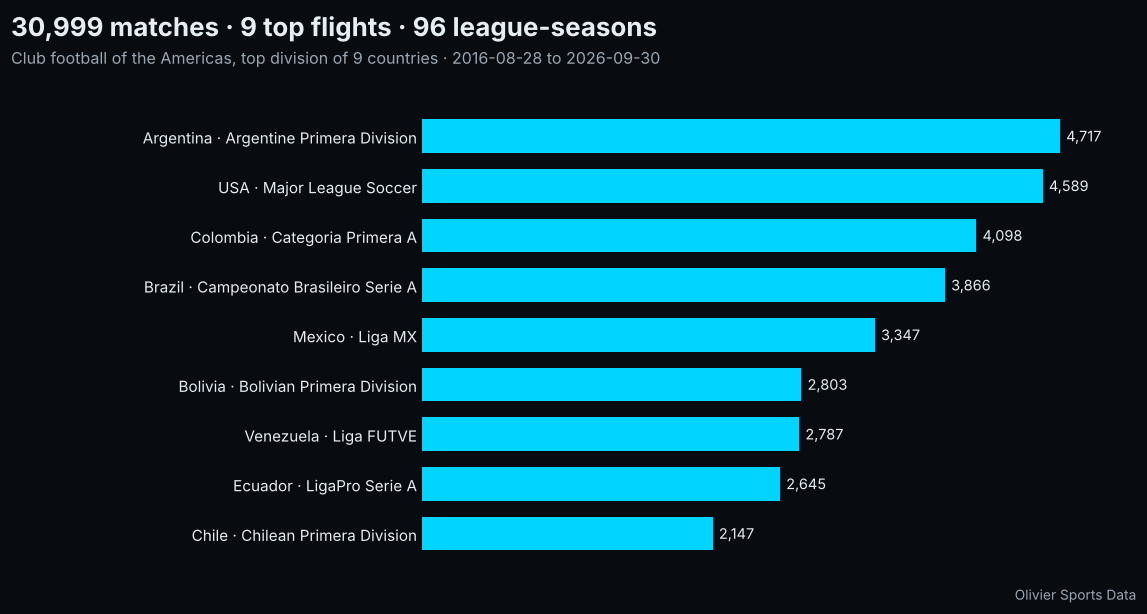

In [5]:
# matches per league (also saved as a PNG: Output tab on Kaggle)
names = M.drop_duplicates("Competition_Code").set_index("Competition_Code")
counts = M["Competition_Code"].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(11, 5.6))
fig.subplots_adjust(left=0.36, right=0.95, top=0.83, bottom=0.06)
ax.barh(range(len(counts)), counts.values, height=0.68, color=CYAN, zorder=2)
ax.set_yticks(range(len(counts)), [f"{names.loc[c, 'Country']} · {names.loc[c, 'Competition']}" for c in counts.index],
              fontsize=10, color=FG)
for i, v in enumerate(counts.values):
    ax.text(v + counts.max() * 0.01, i, f"{v:,}", va="center", fontsize=9.5, color=FG)
ax.set_xlim(0, counts.max() * 1.12)
ax.xaxis.set_visible(False)
ax.grid(False)
ax.tick_params(axis="y", length=0)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
fig.text(0.02, 0.93, f"{len(M):,} matches · {M['Competition_Code'].nunique()} top flights · {len(seasons)} league-seasons",
         fontsize=17, fontweight="bold", color=FG)
fig.text(0.02, 0.885, f"Club football of the Americas, top division of 9 countries · "
         f"{M['Kickoff_UTC'].min()[:10]} to {M['Kickoff_UTC'].max()[:10]}", fontsize=10.5, color=FG2)
fig.text(0.95, 0.015, "Olivier Sports Data", ha="right", fontsize=9, color=FG2)
fig.savefig("matches_per_league.png", dpi=170, facecolor=BG)
plt.show()

## 4 · Opening and closing prices

One row per match. For each book and market: the first and the last valid pre-match quote, each with the time
it was recorded. The listing says a closing price is never an in-play price, so every closing time must sit
strictly before the scheduled kickoff.

In [6]:
head = pd.read_csv(os.path.join(ROOT, "Americas_Opening_Closing_Odds.csv"), nrows=0).columns
OC = pd.read_csv(os.path.join(ROOT, "Americas_Opening_Closing_Odds.csv"),
                 dtype={c: str for c in head if c.endswith(("_Open_Time", "_Close_Time")) or c in ("Match_ID", "Season")})
check("one Opening_Closing row per match, same Match_IDs as Matches",
      len(OC) == len(M) and set(OC["Match_ID"]) == set(M["Match_ID"]))
kick = OC["Kickoff_Epoch"].astype("int64")
late, inverted, n_close = 0, 0, 0
for c in [c for c in OC.columns if c.endswith("_Close_Time")]:
    close = epoch(OC[c]); opened = epoch(OC[c.replace("_Close_", "_Open_")])
    n_close += close.notna().sum()
    late += (close >= kick).sum()
    inverted += (opened > close).sum()
check(f"all {n_close:,} closing times are before the scheduled kickoff", late == 0, f"{late} after")
check("opening time <= closing time everywhere", inverted == 0, f"{inverted} inverted")

cov = {b: int(OC[f"{b}_FT_1X2_Close_Time"].notna().sum()) for b in BOOKS}
check("matches with a FT 1X2 close, per book, as listed", cov == CLAIMS["ft_1x2_close_per_book"],
      " · ".join(f"{b} {n:,}" for b, n in cov.items()))

PASS  one Opening_Closing row per match, same Match_IDs as Matches


PASS  all 357,521 closing times are before the scheduled kickoff   [0 after]
PASS  opening time <= closing time everywhere   [0 inverted]
PASS  matches with a FT 1X2 close, per book, as listed   [Bet365 30,893 · Pinnacle 23,110 · Unibet 28,000 · Betfair 5,857 · Betsson 12,582]


### Coverage by league — share of matches with a FT 1X2 closing price

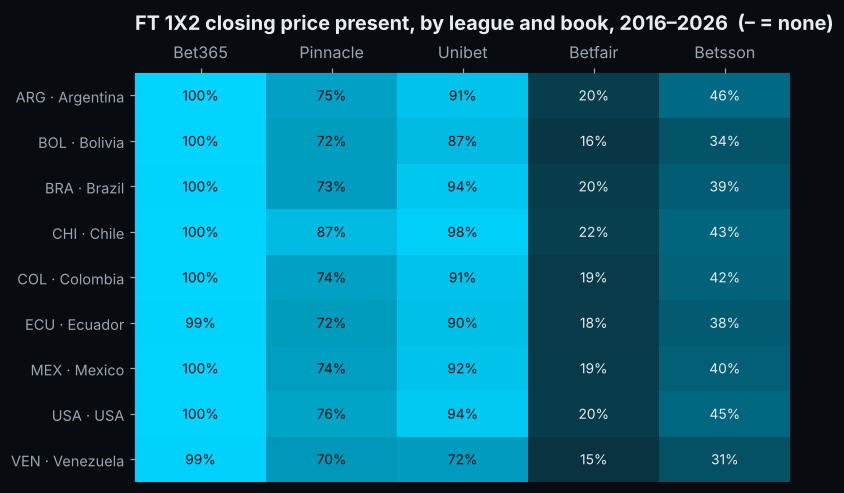

In [7]:
share = pd.DataFrame({b: OC.groupby("Competition_Code")[f"{b}_FT_1X2_Close_Time"].apply(lambda s: s.notna().mean())
                      for b in BOOKS}).reindex(ORDER)
cmap = LinearSegmentedColormap.from_list("cyan", ["#0d1b22", "#00708c", CYAN])
fig, ax = plt.subplots(figsize=(7.4, 4.6))
ax.imshow(share.values, aspect="auto", cmap=cmap, vmin=0, vmax=1)
ax.set_xticks(range(len(BOOKS)), BOOKS)
ax.xaxis.tick_top()
ax.set_yticks(range(len(ORDER)), [f"{c} · {names.loc[c, 'Country']}" for c in ORDER], fontsize=9.5)
ax.grid(False)
for i, c in enumerate(ORDER):
    for j, b in enumerate(BOOKS):
        v = share.loc[c, b]
        ax.text(j, i, "–" if v == 0 else f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="#080c10" if v > 0.6 else FG)
ax.set_title("FT 1X2 closing price present, by league and book, 2016–2026  (– = none)", pad=28)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
plt.tight_layout(); plt.show()

### When is each book in the files?

The README's *Coverage over time* table, recomputed: the share of matches with a FT 1X2 closing price, month by
month (on the matches for which the book was collected), and the same for minute-by-minute statistics and events.
A gap is a month with at least 100 matches in which fewer than half of the matches have it, after the first month
that reaches one half. *Stops for*: a league with nothing after a date, at least 100 matches later.

PASS  first match with each book (FT 1X2 close), with minute stats and with events, as listed   [Bet365 2016-08-28 · Pinnacle 2018-09-27 · Unibet 2017-04-15 · Betfair 2023-11-03 · Betsson 2022-07-03 · Minute_Stats 2017-06-10 · Events 2016-08-28]
PASS  months with a gap, as listed   [Bet365 none · Pinnacle 2023-09..2023-11, 2026-07..2026-08 · Unibet 2026-07..2026-08 · Betfair 2024-11..2025-08, 2026-07..2026-08 · Betsson 2025-12, 2026-07..2026-08 · Minute_Stats 2018-02..2019-09, 2026-07 · Events none]
PASS  no league where a book, the minute stats or the events stop for good   [none]


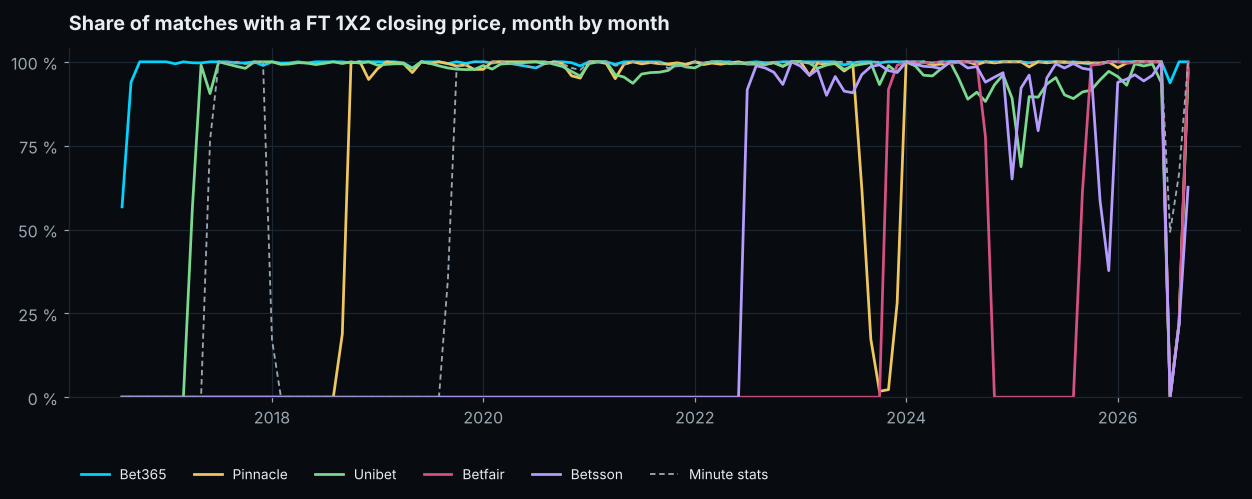

In [8]:
# Betfair and Betsson were not collected for Argentina 2016/17 to 2019/20 and for the 2020 MLS is Back tournament
MI = M.set_index("Match_ID").reindex(OC["Match_ID"])
not_collected = (((MI["Competition_Code"] == "ARG") & MI["Season"].str.contains("/")) |
                 (MI["Tournament"] == "MLS is Back")).to_numpy()
ev_ids = set()
for f in FILES["events"]:
    ev_ids |= set(pd.read_csv(f, usecols=["Match_ID"], dtype=str)["Match_ID"])
month = OC["Kickoff_UTC"].str[:7]
everywhere = np.ones(len(OC), bool)
series = {b: (OC[f"{b}_FT_1X2_Close_Time"].notna().to_numpy(),
              ~not_collected if b in ("Betfair", "Betsson") else everywhere) for b in BOOKS}
series["Minute_Stats"] = (MI["Has_Minute_Stats"].to_numpy() == 1, everywhere)
series["Events"] = (OC["Match_ID"].isin(ev_ids).to_numpy(), everywhere)

def coverage_over_time(present, scope, threshold=0.5, min_matches=100, min_before=50, min_after=100):
    d = pd.DataFrame({"month": month[scope].to_numpy(), "ok": present[scope]})
    first = OC.loc[scope & present, "Kickoff_UTC"].min()[:10]
    g = d.groupby("month")["ok"].agg(["size", "mean"])
    states = [(m, r["mean"] >= threshold) for m, r in g.iterrows() if r["size"] >= min_matches]
    while states and not states[0][1]:
        states.pop(0)
    gaps, cur = [], None
    for m, ok in states:
        if not ok:
            cur = [m, m] if cur is None else [cur[0], m]
        elif cur:
            gaps.append(cur); cur = None
    if cur:
        gaps.append(cur)
    stops = {}
    for c in ORDER:
        mine = OC.loc[scope & (OC["Competition_Code"] == c).to_numpy()]
        hit = mine.loc[present[scope & (OC["Competition_Code"] == c).to_numpy()], "Kickoff_UTC"]
        if len(hit) >= min_before and (mine["Kickoff_UTC"] > hit.max()).sum() >= min_after:
            stops[c] = hit.max()[:10]
    return first, gaps, stops, g["mean"]

timeline, got_from, got_gaps, got_stops = {}, {}, {}, {}
for name, (present, scope) in series.items():
    got_from[name], got_gaps[name], got_stops[name], timeline[name] = coverage_over_time(present, scope)
check("first match with each book (FT 1X2 close), with minute stats and with events, as listed",
      got_from == CLAIMS["coverage_from"], " · ".join(f"{k} {v}" for k, v in got_from.items()))
check("months with a gap, as listed", got_gaps == CLAIMS["coverage_gaps"],
      " · ".join(f"{k} " + (", ".join(a if a == b else f"{a}..{b}" for a, b in v) or "none") for k, v in got_gaps.items()))
check("no league where a book, the minute stats or the events stop for good", got_stops == CLAIMS["coverage_stops"],
      " · ".join(f"{k} {v}" for k, v in got_stops.items() if v) or "none")

fig, ax = plt.subplots(figsize=(11.5, 4.8))
for name in BOOKS:
    s = timeline[name]
    ax.plot(pd.to_datetime(s.index), s.values, color=BOOK_COLOR[name], linewidth=1.8, label=name)
s = timeline["Minute_Stats"]
ax.plot(pd.to_datetime(s.index), s.values, color=FG2, linewidth=1.2, linestyle=(0, (3, 2)), label="Minute stats")
ax.set_ylim(0, 1.04)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1], ["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_title("Share of matches with a FT 1X2 closing price, month by month", pad=12)
ax.legend(loc="lower left", ncol=6, fontsize=9, bbox_to_anchor=(0, -0.28))
plt.tight_layout(); plt.show()

### How close to kickoff is a "closing" price?

A closing quote is the last pre-match price the book published. Books update at different rhythms, so each one
gets its own closing time. Below: median and interquartile range of the gap to kickoff, FT 1X2.

PASS  median closing gap per book, as listed   [Pinnacle 4 min · Betfair 5 min · Betsson 11 min · Bet365 25 min · Unibet 1.7 h]


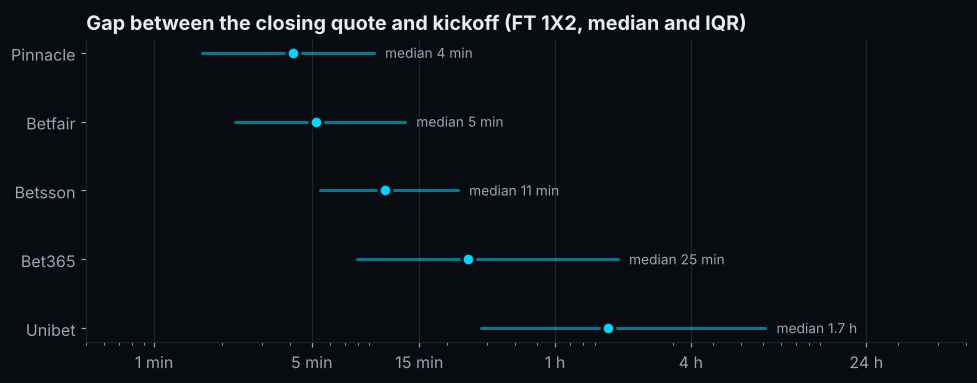

In [9]:
def upper_median(v):
    v = np.sort(np.asarray(v)); return v[len(v) // 2]

def readable(s):
    return f"{s / 3600:.1f} h" if s >= 5400 else f"{s / 60:.0f} min"

gaps = {}
for b in BOOKS:
    g = (kick - epoch(OC[f"{b}_FT_1X2_Close_Time"])).dropna().to_numpy()
    gaps[b] = g
got = {b: readable(upper_median(g)) for b, g in gaps.items()}
check("median closing gap per book, as listed", all(got[b] == CLAIMS["median_close_gap"][b] for b in BOOKS),
      " · ".join(f"{b} {got[b]}" for b in sorted(got, key=lambda b: upper_median(gaps[b]))))

books = sorted(BOOKS, key=lambda b: upper_median(gaps[b]), reverse=True)
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, b in enumerate(books):
    q1, q2, q3 = np.percentile(gaps[b] / 60, [25, 50, 75])
    ax.plot([q1, q3], [i, i], color=CYAN, linewidth=2, solid_capstyle="round", alpha=0.55)
    ax.scatter([q2], [i], s=70, color=CYAN, zorder=3, edgecolor=BG, linewidth=2)
    ax.text(q3 * 1.12, i, f"median {readable(upper_median(gaps[b]))}", va="center", fontsize=9, color=FG2)
ax.set_xscale("log")
ax.set_xticks([1, 5, 15, 60, 240, 1440], ["1 min", "5 min", "15 min", "1 h", "4 h", "24 h"])
ax.set_yticks(range(len(books)), books)
ax.set_xlim(0.5, 4000)
ax.grid(axis="y", visible=False)
ax.set_title("Gap between the closing quote and kickoff (FT 1X2, median and IQR)")
plt.tight_layout(); plt.show()

### Are these real market prices?

A real closing line is better informed than the opening one: its implied probabilities should predict results
better. Probabilities are de-margined proportionally; lower log-loss is better. Compare open and close **within a
book** — books cover different sets of matches, so the rows are not comparable with each other.

In [10]:
y = OC["Result_90"].map({"H": 0, "D": 1, "A": 2}).to_numpy()
rows = []
for b in BOOKS:
    cols = lambda k: [f"{b}_FT_1X2_{k}_{s}" for s in ("Home", "Draw", "Away")]
    o, c = OC[cols("Open")].to_numpy(float), OC[cols("Close")].to_numpy(float)
    ok = ~np.isnan(o).any(1) & ~np.isnan(c).any(1)
    def logloss(x):
        p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
        return -np.log(p[np.arange(ok.sum()), y[ok]]).mean()
    rows.append((b, ok.sum(), logloss(o), logloss(c), (1 / o[ok]).sum(1).mean() - 1, (1 / c[ok]).sum(1).mean() - 1))
LL = pd.DataFrame(rows, columns=["Book", "Matches", "LogLoss open", "LogLoss close", "Margin open", "Margin close"]).set_index("Book")
check("closing beats opening on log-loss, for every book", (LL["LogLoss close"] < LL["LogLoss open"]).all())
LL.style.format({"Matches": "{:,}", "LogLoss open": "{:.4f}", "LogLoss close": "{:.4f}",
                 "Margin open": "{:.2%}", "Margin close": "{:.2%}"})

PASS  closing beats opening on log-loss, for every book


,Matches,LogLoss open,LogLoss close,Margin open,Margin close
Book,,,,,
Bet365,"30,893",1.0192,1.0057,8.51%,6.90%
Pinnacle,"23,110",1.0173,1.0060,6.00%,4.42%
Unibet,"28,000",1.0167,1.0080,8.70%,8.58%
Betfair,"5,857",1.0153,1.0020,8.58%,11.39%
Betsson,"12,582",1.0148,1.0097,6.75%,6.75%


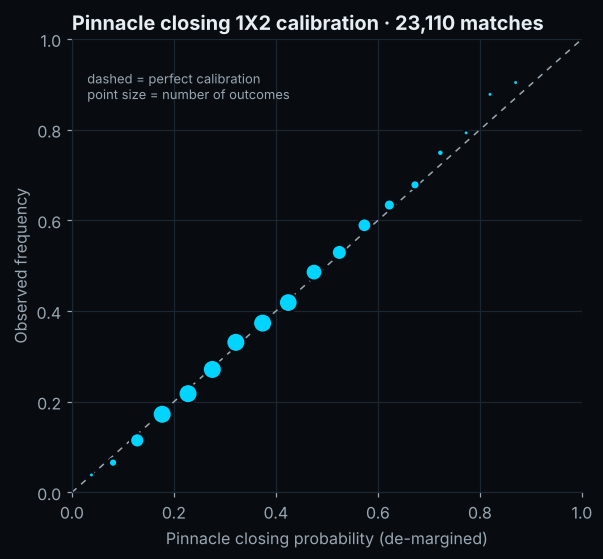

In [11]:
# Pinnacle closing 1X2: predicted probability vs observed frequency (all three outcomes pooled)
cols = [f"Pinnacle_FT_1X2_Close_{s}" for s in ("Home", "Draw", "Away")]
x = OC[cols].to_numpy(float); ok = ~np.isnan(x).any(1)
p = 1 / x[ok]; p = p / p.sum(1, keepdims=True)
hit = np.zeros_like(p); hit[np.arange(ok.sum()), y[ok]] = 1
cal = pd.DataFrame({"p": p.ravel(), "hit": hit.ravel()})
cal["bin"] = pd.cut(cal["p"], np.arange(0, 1.0001, 0.05))
cb = cal.groupby("bin", observed=True).agg(p=("p", "mean"), freq=("hit", "mean"), n=("hit", "size"))
cb = cb[cb["n"] >= 50]
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.plot([0, 1], [0, 1], color=FG2, linewidth=1, linestyle=(0, (4, 4)))
ax.scatter(cb["p"], cb["freq"], s=np.clip(cb["n"] / 30, 12, 160), color=CYAN, edgecolor=BG, linewidth=1.5, zorder=3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.set_xlabel("Pinnacle closing probability (de-margined)"); ax.set_ylabel("Observed frequency")
ax.set_title(f"Pinnacle closing 1X2 calibration · {ok.sum():,} matches")
ax.text(0.03, 0.93, "dashed = perfect calibration\npoint size = number of outcomes", fontsize=8.5, color=FG2, va="top")
plt.tight_layout(); plt.show()

## 5 · 74 million timestamped quotes

One pass over the 9 odds files, a few columns at a time. Checked on every row: a **pre-match** quote carries no
score and was recorded before the scheduled kickoff. The same pass reads the **real start** of each match from
Bet365's live clock (time of the quote minus its minute, minutes 1 to 15): `Kickoff_UTC` is the scheduled kickoff,
and MLS matches start a few minutes after it.

In [12]:
kick_by_id = pd.Series(M["Kickoff_Epoch"].to_numpy("int64"), index=M["Match_ID"].astype("int64"))
comp_by_id = pd.Series(M["Competition_Code"].to_numpy(), index=M["Match_ID"].astype("int64"))
use = ["Match_ID", "Book", "Phase", "Epoch", "Minute", "Score_Home", "Score_Away"]

def read(path, cols):
    try:
        d = pd.read_csv(path, usecols=cols, engine="pyarrow")   # fast, multi-threaded
    except Exception:
        d = pd.read_csv(path, usecols=cols)
    for c in d.columns:   # the pyarrow reader turns ISO times into datetimes: show them as written in the file
        if pd.api.types.is_datetime64_any_dtype(d[c]):
            d[c] = d[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
    return d

t0 = time.time()
by_book_phase, by_book_league, starts, last_pre = [], [], [], []
ip_both, pre_clock, pre_clock_values = {}, {}, set()
pre_scored = pre_late = n_rows = 0
off_manifest = []
for f in FILES["odds"]:
    d = read(f, use)
    n_rows += len(d)
    if len(d) != ROWS.get(stem(f)):
        off_manifest.append(stem(f))
    pre = (d["Phase"] == "Pre-match").to_numpy()
    scored = d["Score_Home"].notna().to_numpy()
    pre_scored += (pre & scored).sum()
    pre_late += (pre & (d["Epoch"].to_numpy() >= kick_by_id.reindex(d["Match_ID"]).to_numpy())).sum()
    clock = d["Minute"].notna().to_numpy()
    both = ~pre & scored & d["Score_Away"].notna().to_numpy() & clock
    for b, n in d.loc[both, "Book"].value_counts().items():
        ip_both[b] = ip_both.get(b, 0) + int(n)
    for b, n in d.loc[pre & clock, "Book"].value_counts().items():
        pre_clock[b] = pre_clock.get(b, 0) + int(n)
    pre_clock_values |= set(d.loc[pre & clock, "Minute"].unique())
    by_book_phase.append(d.groupby(["Book", "Phase"]).size())
    by_book_league.append(d.groupby([d["Book"], comp_by_id.reindex(d["Match_ID"]).to_numpy()]).size())
    clock = d[(d["Book"] == "Bet365") & d["Score_Home"].notna() & d["Score_Away"].notna() & d["Minute"].between(1, 15)]
    starts.append((clock["Epoch"] - 60 * clock["Minute"]).groupby(clock["Match_ID"]).min())
    last_pre.append(d.loc[pre, "Epoch"].groupby(d.loc[pre, "Match_ID"]).max())
    print(f"{os.path.basename(f):42} {len(d):>12,} quotes   {time.time() - t0:5.0f} s")
    del d, clock

bp = pd.concat(by_book_phase).groupby(level=[0, 1]).sum().unstack(fill_value=0)
phase = bp.sum()
check(f"{CLAIMS['quotes']:,} quotes, every file equal to the MANIFEST", n_rows == CLAIMS["quotes"] and not off_manifest,
      f"{n_rows:,}" + (f", off: {', '.join(off_manifest)}" if off_manifest else ""))
check("in-play / pre-match split as listed",
      phase.get("In-play", 0) == CLAIMS["in_play"] and phase.get("Pre-match", 0) == CLAIMS["pre_match"],
      f"{phase.get('In-play', 0):,} in-play · {phase.get('Pre-match', 0):,} pre-match")
check("quotes per book as listed", {b: int(n) for b, n in bp.sum(axis=1).items()} == CLAIMS["quotes_per_book"])
check("no pre-match quote carries a score", pre_scored == 0, f"{pre_scored}")
check("every pre-match quote is before the scheduled kickoff", pre_late == 0, f"{pre_late}")
in_play_book = bp["In-play"] if "In-play" in bp.columns else pd.Series(dtype=int)
got_both = {b: ip_both.get(b, 0) for b in BOOKS}
check(f"score and clock on in-play quotes, book by book, as listed: {sum(got_both.values()) / phase.get('In-play', 1):.1%} of them carry both",
      got_both == CLAIMS["in_play_score_and_clock"],
      " · ".join(f"{b} {got_both[b] / in_play_book.get(b, 1):.1%}" if got_both[b] >= 0.001 * in_play_book.get(b, 1)
                 else f"{b} {got_both[b]} of {in_play_book.get(b, 0):,}" for b in BOOKS))
got_pre_clock = {b: pre_clock.get(b, 0) for b in BOOKS}
check("pre-match quotes carry no clock, except Bet365's minute 0 just before kickoff",
      got_pre_clock == CLAIMS["pre_match_with_minute"] and pre_clock_values <= {0},
      " · ".join(f"{b} {n}" for b, n in got_pre_clock.items() if n) + ", minute " + ", ".join(str(int(x)) for x in sorted(pre_clock_values)))
bp.assign(Total=bp.sum(axis=1)).reindex(BOOKS).style.format("{:,}")

Americas_Odds_Timestamped_ARG.csv.gz         11,126,122 quotes      18 s


Americas_Odds_Timestamped_BOL.csv.gz          5,890,633 quotes      23 s


Americas_Odds_Timestamped_BRA.csv.gz          9,975,255 quotes      34 s


Americas_Odds_Timestamped_CHI.csv.gz          5,194,863 quotes      37 s


Americas_Odds_Timestamped_COL.csv.gz          9,779,571 quotes      47 s


Americas_Odds_Timestamped_ECU.csv.gz          5,648,094 quotes      52 s


Americas_Odds_Timestamped_MEX.csv.gz          8,656,106 quotes      61 s


Americas_Odds_Timestamped_USA.csv.gz         12,697,621 quotes      75 s


Americas_Odds_Timestamped_VEN.csv.gz          4,712,276 quotes      78 s
PASS  73,680,541 quotes, every file equal to the MANIFEST   [73,680,541]
PASS  in-play / pre-match split as listed   [58,887,358 in-play · 14,793,183 pre-match]
PASS  quotes per book as listed
PASS  no pre-match quote carries a score   [0]
PASS  every pre-match quote is before the scheduled kickoff   [0]
PASS  score and clock on in-play quotes, book by book, as listed: 93.7% of them carry both   [Bet365 98.8% · Pinnacle 34 of 211,125 · Unibet 99.4% · Betfair 22.1% · Betsson 98.9%]
PASS  pre-match quotes carry no clock, except Bet365's minute 0 just before kickoff   [Bet365 874, minute 0]


Phase,In-play,Pre-match,Total
Book,,,
Bet365,"49,112,123","4,569,805","53,681,928"
Pinnacle,"211,125","2,355,764","2,566,889"
Unibet,"4,774,706","261,464","5,036,170"
Betfair,"3,717,300","7,033,048","10,750,348"
Betsson,"1,072,104","573,102","1,645,206"


In [13]:
start = pd.concat(starts).groupby(level=0).min()                 # real start, Unix seconds (Bet365 live clock)
lastp = pd.concat(last_pre).groupby(level=0).max()               # last pre-match quote of the match, all books
late_min = (start - kick_by_id.reindex(start.index)) / 60        # real start minus scheduled kickoff, minutes
usa = comp_by_id.reindex(late_min.index) == "USA"
mls_late = int(((late_min > 5) & (late_min <= 30) & usa).sum())
check(f"MLS: on {CLAIMS['mls_start_5_to_30_min_late']:,} of the {CLAIMS['mls_matches']:,} matches the real start is "
      "5 to 30 minutes after the scheduled kickoff",
      mls_late == CLAIMS["mls_start_5_to_30_min_late"] and (M["Competition_Code"] == "USA").sum() == CLAIMS["mls_matches"],
      f"{mls_late:,}, median {late_min[usa].median():.1f} min")
early = late_min[late_min < -180]
check(f"{CLAIMS['source_kickoff_over_3h_late']} matches whose kickoff in the source is more than 3 hours after the real start",
      len(early) == CLAIMS["source_kickoff_over_3h_late"],
      ", ".join(f"{i} {-v / 60:.0f} h" for i, v in early.sort_values().items()))
both = lastp.index.intersection(start.index)
check("no pre-match quote after the real start, on any match with a Bet365 live clock",
      (lastp[both] < start[both]).all(), f"{len(both):,} matches")
summary_late = pd.DataFrame({"league": comp_by_id.reindex(late_min.index), "late": late_min})
(summary_late.groupby("league")["late"]
    .agg(matches_with_clock="size", median_minutes="median",
         start_5_to_30_min_late=lambda s: f"{((s > 5) & (s <= 30)).mean():.0%}",
         start_before_schedule=lambda s: f"{(s < -1).mean():.0%}")
    .round({"median_minutes": 1}))

PASS  MLS: on 4,405 of the 4,589 matches the real start is 5 to 30 minutes after the scheduled kickoff   [4,405, median 9.4 min]
PASS  7 matches whose kickoff in the source is more than 3 hours after the real start   [9305011 47 h, 9305020 46 h, 11344252 19 h, 6236613 18 h, 10094894 17 h, 9397560 13 h, 11903701 3 h]
PASS  no pre-match quote after the real start, on any match with a Bet365 live clock   [30,762 matches]


,matches_with_clock,median_minutes,start_5_to_30_min_late,start_before_schedule
league,,,,
ARG,4700,1.0,4%,3%
BOL,2790,1.0,6%,12%
BRA,3844,0.4,1%,1%
CHI,2137,1.0,2%,3%
COL,4069,0.8,3%,2%
ECU,2627,0.5,0%,3%
MEX,3326,2.0,17%,0%
USA,4569,9.4,96%,0%
VEN,2722,1.7,22%,5%


Quotes per match, all markets, by league: how often each book updated its prices.

In [14]:
bl = pd.concat(by_book_league).groupby(level=[0, 1]).sum().unstack(level=0, fill_value=0).reindex(index=ORDER, columns=BOOKS)
matches_per_league = M.groupby("Competition_Code").size()
(bl.div(matches_per_league, axis=0)).round(0).astype(int).rename_axis("Quotes per match").style.format("{:,}")

Book,Bet365,Pinnacle,Unibet,Betfair,Betsson
Quotes per match,,,,,
ARG,"1,777",74,170,276,61
BOL,"1,693",58,127,188,36
BRA,"1,765",112,175,464,64
CHI,"1,749",84,154,377,55
COL,"1,743",76,178,334,56
ECU,"1,602",68,142,287,36
MEX,"1,821",90,177,439,61
USA,"1,888",117,195,506,61
VEN,"1,376",41,103,142,28


### 37 more bookmakers: dated snapshots

`Bookmaker_Snapshots` holds the first price the source kept for each other bookmaker (`Open`) and its latest
snapshot that is still pre-match (`Last_Pre_Match`). A dated snapshot, not a closing price: the minutes before
kickoff are given on every row.

In [15]:
ids = set(M["Match_ID"].astype("int64"))
parts, off = [], []
for f in FILES["snapshots"]:
    d = read(f, ["Match_ID", "Book", "Market", "Snapshot", "Minutes_Before_Kickoff"])
    if len(d) != ROWS.get(stem(f)):
        off.append(stem(f))
    parts.append(d)
S = pd.concat(parts, ignore_index=True); del parts
check(f"{CLAIMS['snapshots']:,} snapshot rows, all joined to a match", len(S) == CLAIMS["snapshots"] and S["Match_ID"].isin(ids).all()
      and not off, f"{len(S):,}" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
check(f"{CLAIMS['snapshot_books']} bookmakers, none of the 5 main books",
      S["Book"].nunique() == CLAIMS["snapshot_books"] and not set(S["Book"]) & set(BOOKS + ["Betfair (Sportsbook)"]),
      f"{S['Book'].nunique()} books")
check("every snapshot is pre-match (Minutes_Before_Kickoff >= 0)", (S["Minutes_Before_Kickoff"] >= 0).all())
last = S[S["Snapshot"] == "Last_Pre_Match"]
print(f"{S['Match_ID'].nunique():,} matches, {S.groupby('Match_ID')['Book'].nunique().mean():.1f} bookmakers per match on average")
(last.groupby("Market")["Minutes_Before_Kickoff"]
     .agg(rows="size", median_minutes_before_kickoff="median",
          within_60_min=lambda s: f"{(s <= 60).mean():.0%}", over_24_h=lambda s: f"{(s > 1440).mean():.0%}"))

PASS  1,781,722 snapshot rows, all joined to a match   [1,781,722]


PASS  37 bookmakers, none of the 5 main books   [37 books]
PASS  every snapshot is pre-match (Minutes_Before_Kickoff >= 0)


29,947 matches, 14.3 bookmakers per match on average


,rows,median_minutes_before_kickoff,within_60_min,over_24_h
Market,,,,
FT_1X2,418120,141.0,44%,26%
FT_Asian_Handicap,185593,308.0,42%,31%
FT_Total_Goals,287260,216.0,41%,31%


### Lineups, events, minute-by-minute stats

Rows counted from the files themselves, and every row must join a match of `Americas_Matches` on `Match_ID`.
The Bolivia and Venezuela lineup files hold only their header: the source has no lineups for these two leagues.

In [16]:
timed, untimed, rows_untimed = set(), set(), 0
for folder, claim in (("lineups", "lineups"), ("events", "events"), ("minute_stats", "minute_stats")):
    n, orphans, off = 0, 0, []
    for f in FILES[folder]:
        d = read(f, ["Match_ID", "Timestamp_UTC"] if folder == "minute_stats" else ["Match_ID"])
        if folder == "minute_stats":
            has = d["Timestamp_UTC"].notna()
            timed |= set(d.loc[has, "Match_ID"]); untimed |= set(d.loc[~has, "Match_ID"])
            rows_untimed += int((~has).sum())
        n += len(d)
        orphans += (~d["Match_ID"].isin(ids)).sum()
        if len(d) != ROWS.get(stem(f)):
            off.append(stem(f))
    check(f"{CLAIMS[claim]:,} {folder.replace('_', ' ')} rows, all joined to a match", n == CLAIMS[claim] and orphans == 0 and not off,
          f"{n:,} rows, {orphans} without a match" + (f", off the MANIFEST: {', '.join(off)}" if off else ""))
kick_utc = M.set_index(M["Match_ID"].astype("int64"))["Kickoff_UTC"]
first_timed = kick_utc.reindex(list(timed)).min()
T = CLAIMS["minute_stats_time"]
check(f"minute-by-minute statistics carry their recording time from {T['from']}, never before, always after",
      first_timed[:10] == T["from"] and not (timed & untimed) and kick_utc.reindex(list(untimed)).max() < first_timed
      and len(untimed) == T["matches_without"] and rows_untimed == T["rows_without"],
      f"first {first_timed[:10]}; {len(untimed):,} matches and {rows_untimed:,} rows without time")

PASS  983,966 lineups rows, all joined to a match   [983,966 rows, 0 without a match]


PASS  954,808 events rows, all joined to a match   [954,808 rows, 0 without a match]


PASS  8,353,269 minute stats rows, all joined to a match   [8,353,269 rows, 0 without a match]
PASS  minute-by-minute statistics carry their recording time from 2021-05-11, never before, always after   [first 2021-05-11; 5,535 matches and 2,102,874 rows without time]


## 6 · One match, quote by quote

The match shown in the listing: Minnesota United 3-3 Seattle Sounders, MLS Round One, game 3 of the
best-of-three series, 8 November 2025. Seattle led 2-0 after 8 minutes, Minnesota played the second half with ten
men, led 3-2, conceded the 3-3 at 88' and won the shoot-out 7-6. Bet365 full-time 1X2 in
play, recomputed here from `Americas_Odds_Timestamped_USA.csv.gz`, then drawn as implied probabilities, with the
goals and the red card of the events table on top. The events table and Bet365's clock count minutes each in their
own way and can differ by one minute: clocks are delivered as the bookmaker sent them, never adjusted.

In [17]:
MID = 10862382
row = M[M["Match_ID"] == str(MID)].iloc[0]
check("the Matches row: Minnesota United 1-2 at half-time, 3-3 after 90 minutes, shoot-out 7-6, game 3 (Leg 3), home ground",
      (row["Home_Goals_HT"], row["Away_Goals_HT"], row["Home_Goals_90"], row["Away_Goals_90"], row["Home_Penalties"],
       row["Away_Penalties"], row["Extra_Time"], row["Leg"], row["Neutral_Venue"])
      == (1, 2, 3, 3, 7, 6, 0, 3, 0))
cols = ["Match_ID", "Book", "Market", "Phase", "Timestamp_UTC", "Epoch", "Minute",
        "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]
usa_odds = read(next(f for f in FILES["odds"] if stem(f).endswith("_USA")), cols)
one = usa_odds[usa_odds["Match_ID"] == MID]
del usa_odds
print(one.groupby(["Book", "Phase"]).size().unstack(fill_value=0))
t = one[(one["Book"] == "Bet365") & (one["Market"] == "FT_1X2") & (one["Phase"] == "In-play")].sort_values("Epoch", kind="stable")
t = t.reset_index(drop=True)
check(f"{CLAIMS['example_in_play_bet365_1x2']} in-play Bet365 1X2 quotes on this match",
      len(t) == CLAIMS["example_in_play_bet365_1x2"], f"{len(t)}")
real = start[MID]
check("scheduled at " + row["Kickoff_UTC"][11:16] + " UTC, real start "
      + pd.Timestamp(real, unit="s").strftime("%H:%M:%S") + " (Bet365 clock): the first in-play quote, before it, has no score",
      row["Kickoff_Epoch"] < t["Epoch"].iloc[0] < real and pd.isna(t["Score_Home"].iloc[0]))

# the listing's rule: around each score change, the quote before and the quote at the change
keep, last = [], None
for i, sc in enumerate(zip(t["Score_Home"].fillna(-1), t["Score_Away"].fillna(-1))):
    if sc != last:
        keep += [k for k in (i - 1, i) if k >= 0 and k not in keep]
        last = sc
show = (t.loc[keep[:16], ["Timestamp_UTC", "Minute", "Score_Home", "Score_Away", "Price_Home", "Price_Draw", "Price_Away", "Suspended"]]
          .astype({"Minute": "Int64", "Score_Home": "Int64", "Score_Away": "Int64"}))
show

PASS  the Matches row: Minnesota United 1-2 at half-time, 3-3 after 90 minutes, shoot-out 7-6, game 3 (Leg 3), home ground


Phase     In-play  Pre-match
Book                        
Bet365       1745         76
Betfair       611        170
Betsson       106          4
Pinnacle        0         54
Unibet        217          8
PASS  255 in-play Bet365 1X2 quotes on this match   [255]
PASS  scheduled at 21:00 UTC, real start 21:12:56 (Bet365 clock): the first in-play quote, before it, has no score


,Timestamp_UTC,Minute,Score_Home,Score_Away,Price_Home,Price_Draw,Price_Away,Suspended
0,2025-11-08T21:03:25Z,<NA>,<NA>,<NA>,3.1,3.400,2.250,0
1,2025-11-08T21:16:08Z,3,0,0,3.1,3.400,2.300,0
2,2025-11-08T21:16:51Z,3,0,0,3.1,3.250,2.300,0
3,2025-11-08T21:18:03Z,5,0,1,NaN,NaN,NaN,1
6,2025-11-08T21:19:17Z,6,0,1,6.0,4.333,1.500,0
7,2025-11-08T21:20:43Z,7,0,2,NaN,NaN,NaN,1
8,2025-11-08T21:20:57Z,8,0,1,6.0,4.333,1.500,0
9,2025-11-08T21:21:02Z,8,0,2,NaN,NaN,NaN,1
31,2025-11-08T21:32:03Z,19,0,2,19.0,8.000,1.125,0
32,2025-11-08T21:32:10Z,19,1,2,8.0,4.500,1.400,0


 Minute  Added_Time Event_Type Team_Side    Player
    5.0         NaN       Goal      Away    Rusnak
    8.0         NaN       Goal      Away  Musovski
   19.0         NaN       Goal      Home   Pereyra
   41.0         NaN   Red Card      Home   Rosales
   62.0         NaN       Goal      Home      Diaz
   71.0         NaN       Goal      Home Markanich
   88.0         NaN       Goal      Away    Morris
shoot-out kicks in the events table: 20


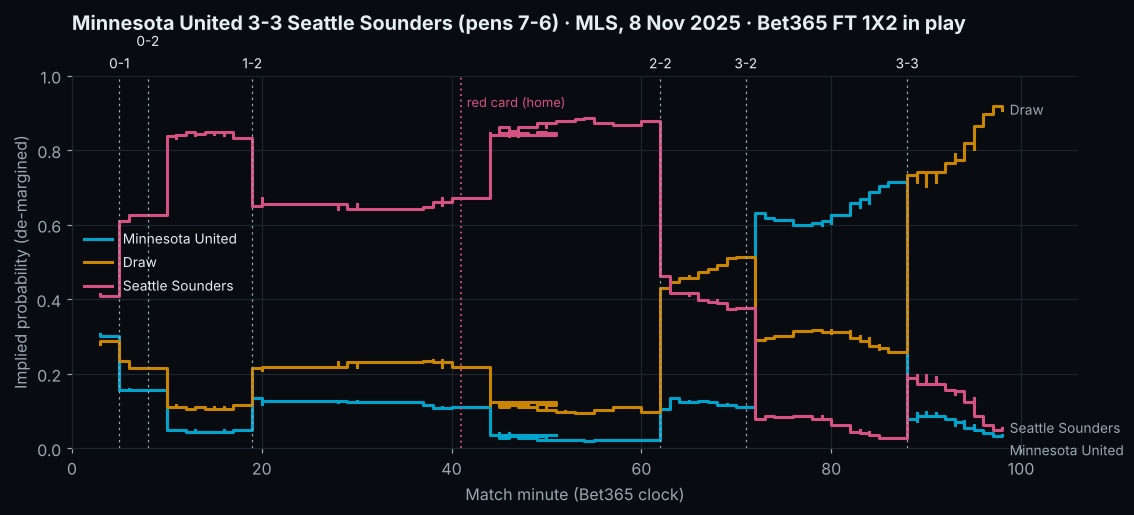

In [18]:
ev = read(next(f for f in FILES["events"] if stem(f).endswith("_USA")),
          ["Match_ID", "Minute", "Added_Time", "Event_Type", "Team_Side", "Player"])
mine = ev[(ev["Match_ID"] == MID)]
goals = mine[mine["Event_Type"] == "Goal"].sort_values(["Minute", "Added_Time"], na_position="first")
reds = mine[mine["Event_Type"] == "Red Card"]
print(pd.concat([goals, reds]).sort_values("Minute")[["Minute", "Added_Time", "Event_Type", "Team_Side", "Player"]]
      .to_string(index=False))
print(f"shoot-out kicks in the events table: {mine['Event_Type'].str.startswith('Penalty Shootout').sum()}")

live = t[(t["Suspended"] == 0) & t["Minute"].notna()].copy()
inv = 1 / live[["Price_Home", "Price_Draw", "Price_Away"]]
prob = inv.div(inv.sum(axis=1), axis=0)
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = live["Minute"]
names_hda = {"Price_Home": "Minnesota United", "Price_Draw": "Draw", "Price_Away": "Seattle Sounders"}
for col, side in zip(prob.columns, ["Home", "Draw", "Away"]):
    ax.plot(x, prob[col], color=HDA[side], linewidth=2, label=names_hda[col], drawstyle="steps-post")
ends = sorted(((prob[col].iloc[-1], col) for col in prob.columns), reverse=True)
y_lab = []
for v, col in ends:                                   # end labels kept at least 0.06 apart
    y_lab.append(min(v, y_lab[-1] - 0.06) if y_lab else v)
    ax.text(x.iloc[-1] + 0.8, y_lab[-1], names_hda[col], color=FG2, fontsize=9, va="center")
score_h = score_a = 0
previous, level = -99, 0
for _, g in goals.iterrows():
    m = g["Minute"] + (0 if pd.isna(g["Added_Time"]) else g["Added_Time"])
    score_h += g["Team_Side"] == "Home"; score_a += g["Team_Side"] == "Away"
    level = 1 - level if m - previous < 5 else 0          # stagger labels of goals close together
    previous = m
    ax.axvline(m, color=FG2, linewidth=0.8, linestyle=(0, (2, 3)))
    ax.text(m, 1.02 + 0.06 * level, f"{score_h}-{score_a}", ha="center", fontsize=9, color=FG,
            transform=ax.get_xaxis_transform())
for _, g in reds.iterrows():
    ax.axvline(g["Minute"], color=HDA["Away"], linewidth=1.2, linestyle=(0, (1, 2)))
    ax.text(g["Minute"] + 0.6, 0.95, f"red card ({g['Team_Side'].lower()})", fontsize=8.5, color=HDA["Away"],
            transform=ax.get_xaxis_transform(), va="top")
ax.set_ylim(0, 1); ax.set_xlim(0, max(97, x.max() + 8))
ax.set_xlabel("Match minute (Bet365 clock)"); ax.set_ylabel("Implied probability (de-margined)")
ax.set_title("Minnesota United 3-3 Seattle Sounders (pens 7-6) · MLS, 8 Nov 2025 · Bet365 FT 1X2 in play", pad=30)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout(); plt.show()

## 7 · Nothing a spreadsheet can reinterpret

Formations are digits (4231 = 4-2-3-1), timestamps carry the T and the Z, seasons read 2016/17 or 2019, and no
text cell starts with a character a spreadsheet would read as a formula or turn into a date.

In [19]:
iso = re.compile(r"^\d{4}-\d{2}-\d{2}T\d{2}:\d{2}:\d{2}Z$")
risky = re.compile(r"^([=+@\-]|\d{1,2}[-/]\d{1,2}([-/]\d{2,4})?$|\d{1,2}:\d{2}(:\d{2})?$)")
form = pd.concat([M["Home_Formation"], M["Away_Formation"]]).dropna()
check("formations are digits that add up to 10 players",
      form.str.fullmatch(r"\d{3,5}").all() and form.map(lambda s: sum(map(int, s)) == 10).all(),
      f"{len(form):,} formations, e.g. {form.value_counts().index[0]}")
times = pd.concat([M["Kickoff_UTC"]] + [OC[c].dropna() for c in OC.columns if c.endswith(("_Open_Time", "_Close_Time"))])
check("every timestamp is ISO 8601 with T and Z", times.map(lambda s: bool(iso.match(s))).all(), f"{len(times):,} cells")
TS = pd.read_csv(os.path.join(ROOT, "Americas_Team_Stats.csv"), dtype=str)
is_text = lambda s: s.dtype == object or isinstance(s.dtype, pd.StringDtype)
text_cells = pd.concat([df[c].dropna().astype(str) for df in (M, OC, TS) for c in df.columns if is_text(df[c])
                        and not c.endswith(("_Open_Time", "_Close_Time", "_UTC"))])
bad = text_cells[text_cells.map(lambda s: bool(risky.match(s)))]
check("no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)", bad.empty,
      f"{len(text_cells):,} text cells" + (f", e.g. {bad.iloc[0]!r}" if len(bad) else ""))
check(f"{CLAIMS['team_stats']:,} team-stat rows, two per match", len(TS) == CLAIMS["team_stats"] == 2 * len(M))

PASS  formations are digits that add up to 10 players   [29,497 formations, e.g. 4231]


PASS  every timestamp is ISO 8601 with T and Z   [746,041 cells]


PASS  no text cell a spreadsheet would rewrite (Matches, Opening_Closing, Team_Stats)   [2,522,216 text cells]
PASS  61,998 team-stat rows, two per match


## 8 · Summary

In [20]:
summary = pd.DataFrame(RESULTS, columns=["Claim", "Pass", "Detail"])
print(f"{summary['Pass'].sum()} / {len(summary)} claims verified")
summary.assign(Result=summary["Pass"].map({True: "PASS", False: "FAIL"}))[["Result", "Claim", "Detail"]].style.hide(axis="index")

48 / 48 claims verified


Result,Claim,Detail
PASS,all 54 files present,
PASS,every SHA-256 matches the MANIFEST,
PASS,"30,999 matches","30,999"
PASS,Match_ID is unique,
PASS,"9 top flights (club football, division 1), 96 league-seasons, 143 editions (a season, or a tournament inside it: Apertura, Clausura...)",9 / 96 / 143
PASS,"matches per league, as listed",
PASS,"first kickoff on 2016-08-28, last before 2026-10-01",2016-08-28T00:00:00Z to 2026-09-30T23:30:00Z
PASS,Season reads 2016/17 (two calendar years) or 2019 (one),"2016, 2016/17, 2017, 2017/18..."
PASS,Leg only in knockout stages; every game of an MLS best-of-three series numbered,
PASS,"911 knockout matches: 262 single matches, 288 two-legged ties (1 decided by a third match), 7 ties with only their second leg and 5 with only their first, 24 MLS best-of-three series (60 games)",matches 911 · single 262 · two_legged_ties 288 · third_matches 1 · lone_second_legs 7 · lone_first_legs 5 · bo3_series 24 · bo3_games 60


---

Everything above ran on the files a buyer downloads. The README in the ZIP holds the full column dictionary,
the seasons, tournaments and stages of every league, the coverage tables (by league, by book, over time), the
removed source events with their evidence, and every known limitation.

👉 ⚽ **[→ Get the full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/diswpw?utm_source=github&utm_medium=notebook&utm_campaign=americas_premium&utm_content=notebook_bottom)** 👈

A question before buying: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*